# 06A2 FORCE all class probability redistribution MEMORY TIE SAFE FIXED

> Saved outputs are from an earlier local run. Portable path edits have **not** been re-executed. See the repository README for setup and scientific limitations.


In [1]:
import sys
import subprocess
import importlib.util

required_packages = {
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "sklearn": "scikit-learn",
    "scipy": "scipy",
    "joblib": "joblib",
    "pyarrow": "pyarrow",
}

for module_name, package_name in required_packages.items():
    if importlib.util.find_spec(module_name) is None:
        print(f"Installing {package_name} ...")
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", package_name]
        )

print("All required packages are available.")

All required packages are available.


In [2]:
from pathlib import Path
import gc
import hashlib
import json
import math
import platform
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython.display import display

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 300)
pd.set_option("display.max_rows", 300)
pd.set_option("display.max_colwidth", 300)

EPS = 1e-12
ARGMAX_TIE_TOL = 1e-12
RANDOM_STATE = 142
np.random.seed(RANDOM_STATE)

In [3]:
RUN_MODE = "full"  # "pilot" or "full"

ALL_FOLDS = [1, 2, 3, 4, 5]
ACTIVE_FOLDS = [1] if RUN_MODE == "pilot" else ALL_FOLDS

DOSES = [0.25, 0.50, 0.75, 1.00]

RAW8_FEATURES = [
    "GR",
    "NPHI",
    "RHOB",
    "DTC",
    "RDEP",
    "CALI",
    "PEF",
    "SP",
]

# در Pilot Probability تمام کلاس‌ها برای تک‌تک ردیف‌ها ذخیره می‌شود.
# در Full فقط Summaryها ذخیره می‌شوند تا حجم دیسک کنترل شود.
SAVE_ROW_LEVEL_ALL_CLASS = RUN_MODE == "pilot"

PREDICTION_BATCH_SIZE = 150_000
BOOTSTRAP_REPLICATES = 2_000 if RUN_MODE == "pilot" else 1_000
SKIP_COMPLETED_CONDITIONS = True

# Portable paths: override them with environment variables if upstream artifacts
# live outside this repository. See README -> Reproduction & paths.
import os

def _find_stratashift_root():
    start = Path(os.environ.get("STRATASHIFT_REPO_ROOT", Path.cwd())).expanduser().resolve()
    for candidate in (start, *start.parents):
        if (candidate / "notebooks" / "interventions").is_dir() and (candidate / "README.md").is_file():
            return candidate
    raise FileNotFoundError(
        "StrataShift root not found. Launch Jupyter inside the repository "
        "or set STRATASHIFT_REPO_ROOT."
    )

REPO_ROOT = _find_stratashift_root()
TRAIN_PATH = Path(os.environ.get(
    "STRATASHIFT_TRAIN_CSV", str(REPO_ROOT / "data" / "raw" / "train.csv")
)).expanduser().resolve()
PROJECT = Path(os.environ.get(
    "STRATASHIFT_ARTIFACT_ROOT", str(REPO_ROOT / "artifacts")
)).expanduser().resolve()

FOLD_PATH = (
    PROJECT
    / "01_clean_splits_support"
    / "10_grouped_5fold_well_assignment.csv"
)

D04 = (
    PROJECT
    / "04C_shared_class_conditional_transport_bank"
    / "full"
)

BANK_DIR = D04 / "transport_bank"

D05B = (
    PROJECT
    / "05B_raw_log_RF_grouped_well_CV"
    / "full"
)

MODEL_DIR = D05B / "models"

D05C = (
    PROJECT
    / "05C_raw_RF_strict_nested_temperature_calibration"
    / "full"
)

FILE12 = D05C / "12_calibrated_OOF_predictions_raw8.parquet"
TEMP_MAP_PATH = D05C / "11_temperature_map.json"
GATE05C_PATH = D05C / "13_stage_gate.json"

D06A = (
    PROJECT
    / "06A_raw_RF_class_conditional_transport_interventions"
    / RUN_MODE
)

SELECTED_CONDITIONS_PATH = (
    D06A
    / "01_selected_intervention_conditions.csv"
)

GATE06A_PATH = D06A / "11_stage_gate.json"

OUT = (
    PROJECT
    / "06A2_all_class_probability_redistribution"
    / RUN_MODE
)

COND_DIR = OUT / "condition_outputs"
ROW_DIR = OUT / "row_level_all_class"
WELL_DIR = OUT / "per_well_all_class"
PLOT_DIR = OUT / "plots"

for directory in [
    OUT,
    COND_DIR,
    ROW_DIR,
    WELL_DIR,
    PLOT_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )

SENTINELS = {
    "SP": [-999.0],
}

POSITIVE_ONLY = {
    "RDEP",
}

required_paths = [
    TRAIN_PATH,
    FOLD_PATH,
    BANK_DIR,
    MODEL_DIR,
    FILE12,
    TEMP_MAP_PATH,
    GATE05C_PATH,
    SELECTED_CONDITIONS_PATH,
    GATE06A_PATH,
]

missing_paths = [
    str(path)
    for path in required_paths
    if not path.exists()
]

if missing_paths:
    raise FileNotFoundError(
        "Missing inputs:\n"
        + "\n".join(
            missing_paths
        )
    )

print("RUN_MODE:", RUN_MODE)
print("ACTIVE_FOLDS:", ACTIVE_FOLDS)
print("SAVE_ROW_LEVEL_ALL_CLASS:", SAVE_ROW_LEVEL_ALL_CLASS)
print("OUTPUT:", OUT)

RUN_MODE: full
ACTIVE_FOLDS: [1, 2, 3, 4, 5]
SAVE_ROW_LEVEL_ALL_CLASS: False
OUTPUT: <ARTIFACT_ROOT>/06A2_all_class_probability_redistribution/full


In [4]:
def sha256_file(
    path,
    chunk_size=1024 * 1024,
):
    digest = hashlib.sha256()

    with open(path, "rb") as file:
        while True:
            chunk = file.read(chunk_size)

            if not chunk:
                break

            digest.update(chunk)

    return digest.hexdigest()


def dose_col(alpha):
    return (
        f"value_alpha_{float(alpha):.2f}"
        .replace(".", "_")
    )


def safe_class_name(name):
    return (
        str(name)
        .replace("/", "_")
        .replace(" ", "_")
        .replace("-", "_")
    )


def stable_seed(*parts):
    text = "||".join(
        str(part)
        for part in parts
    )

    return int(
        hashlib.sha256(
            text.encode("utf-8")
        ).hexdigest()[:8],
        16,
    )


def bootstrap_mean_ci(
    values,
    replicates,
    seed,
    confidence=0.95,
):
    values = np.asarray(
        values,
        dtype=np.float64,
    )

    values = values[
        np.isfinite(values)
    ]

    if len(values) == 0:
        return np.nan, np.nan, np.nan

    if len(values) == 1:
        value = float(values[0])
        return value, value, value

    rng = np.random.default_rng(seed)

    indices = rng.integers(
        0,
        len(values),
        size=(
            replicates,
            len(values),
        ),
    )

    means = values[indices].mean(axis=1)

    alpha = (
        1.0
        - confidence
    ) / 2.0

    return (
        float(values.mean()),
        float(np.quantile(means, alpha)),
        float(np.quantile(means, 1.0 - alpha)),
    )


def entropy_rows(probabilities):
    probabilities = np.asarray(
        probabilities,
        dtype=np.float64,
    )

    clipped = np.clip(
        probabilities,
        EPS,
        1.0,
    )

    return -np.sum(
        clipped
        * np.log(clipped),
        axis=1,
    )


def jensen_shannon_rows(
    p,
    q,
):
    p = np.asarray(
        p,
        dtype=np.float64,
    )

    q = np.asarray(
        q,
        dtype=np.float64,
    )

    p = np.clip(
        p,
        EPS,
        1.0,
    )

    q = np.clip(
        q,
        EPS,
        1.0,
    )

    p = p / p.sum(
        axis=1,
        keepdims=True,
    )

    q = q / q.sum(
        axis=1,
        keepdims=True,
    )

    midpoint = 0.5 * (
        p + q
    )

    return 0.5 * (
        np.sum(
            p
            * np.log(
                p / midpoint
            ),
            axis=1,
        )
        + np.sum(
            q
            * np.log(
                q / midpoint
            ),
            axis=1,
        )
    )


def total_variation_rows(
    p,
    q,
):
    return 0.5 * np.sum(
        np.abs(
            np.asarray(p)
            - np.asarray(q)
        ),
        axis=1,
    )

# 3. Upstream audit

In [5]:
with open(
    GATE05C_PATH,
    "r",
    encoding="utf-8",
) as file:
    gate_05c = json.load(file)

with open(
    GATE06A_PATH,
    "r",
    encoding="utf-8",
) as file:
    gate_06a = json.load(file)

with open(
    TEMP_MAP_PATH,
    "r",
    encoding="utf-8",
) as file:
    temperature_map = json.load(file)

upstream_audit = {
    "05C_passed": bool(
        gate_05c.get(
            "overall_strict_nested_temperature_calibration_passed",
            False,
        )
    ),
    "06A_passed": bool(
        gate_06a.get(
            "overall_raw_RF_transport_intervention_stage_passed",
            False,
        )
    ),
    "06A_run_mode_matches": (
        gate_06a.get("run_mode")
        == RUN_MODE
    ),
    "file12_exists": FILE12.exists(),
    "raw8_temperatures_complete": (
        set(
            temperature_map.get(
                "raw8",
                {}
            ).keys()
        )
        == {
            str(fold)
            for fold in ALL_FOLDS
        }
    ),
}

print(
    json.dumps(
        upstream_audit,
        indent=2,
    )
)

if not all(
    upstream_audit.values()
):
    raise RuntimeError(
        "Upstream audit failed."
    )

{
  "05C_passed": true,
  "06A_passed": true,
  "06A_run_mode_matches": true,
  "file12_exists": true,
  "raw8_temperatures_complete": true
}


In [6]:
def detect_csv(path):
    for encoding in [
        "utf-8",
        "latin1",
        "iso-8859-1",
        "cp1252",
    ]:
        try:
            with open(
                path,
                "r",
                encoding=encoding,
            ) as file:
                lines = [
                    file.readline()
                    for _ in range(5)
                ]

            if any("," in line for line in lines):
                separator = ","
            elif any(";" in line for line in lines):
                separator = ";"
            elif any("\t" in line for line in lines):
                separator = "\t"
            else:
                separator = ","

            return separator, encoding

        except UnicodeDecodeError:
            continue

    return ",", "utf-8"


separator, encoding = detect_csv(
    TRAIN_PATH
)

train = pd.read_csv(
    TRAIN_PATH,
    sep=separator,
    encoding=encoding,
    low_memory=False,
)

train["ORIGINAL_ROW_ID"] = np.arange(
    len(train),
    dtype=np.int64,
)

fold_raw = pd.read_csv(
    FOLD_PATH
)

well_column = [
    column
    for column in fold_raw.columns
    if column.upper() == "WELL"
][0]

fold_column = [
    column
    for column in fold_raw.columns
    if (
        "FOLD" in column.upper()
        and "SCORE" not in column.upper()
    )
][0]

fold_table = (
    fold_raw[
        [
            well_column,
            fold_column,
        ]
    ]
    .rename(
        columns={
            well_column: "WELL",
            fold_column: "GROUP_FOLD",
        }
    )
    .drop_duplicates(
        subset=["WELL"]
    )
)

fold_table["GROUP_FOLD"] = pd.to_numeric(
    fold_table["GROUP_FOLD"],
    errors="raise",
).astype(int)

train["GROUP_FOLD"] = train["WELL"].map(
    dict(
        zip(
            fold_table["WELL"],
            fold_table["GROUP_FOLD"],
        )
    )
)

if train["GROUP_FOLD"].isna().any():
    raise RuntimeError(
        "Some wells have no fold assignment."
    )

train["GROUP_FOLD"] = train[
    "GROUP_FOLD"
].astype(int)

TARGET_COLUMN = (
    "FORCE_2020_LITHOFACIES_LITHOLOGY"
)

train["LITHOLOGY_CODE"] = pd.to_numeric(
    train[TARGET_COLUMN],
    errors="raise",
).astype(np.int64)

CLASSES = np.array([
    30000,
    65000,
    65030,
    70000,
    70032,
    74000,
    80000,
    86000,
    88000,
    90000,
    93000,
    99000,
], dtype=np.int64)

CLASS_NAMES = {
    30000: "Sandstone",
    65000: "Shale",
    65030: "Sandstone/Shale",
    70000: "Limestone",
    70032: "Chalk",
    74000: "Dolomite",
    80000: "Marl",
    86000: "Anhydrite",
    88000: "Halite",
    90000: "Coal",
    93000: "Basement",
    99000: "Tuff",
}

CLASS_TO_INDEX = {
    int(code): index
    for index, code in enumerate(CLASSES)
}


def clean_series(
    dataframe,
    feature,
):
    values = pd.to_numeric(
        dataframe[feature],
        errors="coerce",
    ).astype(float)

    for sentinel in SENTINELS.get(
        feature,
        [],
    ):
        values.loc[
            np.isclose(
                values.to_numpy(float),
                sentinel,
                rtol=0.0,
                atol=1e-12,
                equal_nan=False,
            )
        ] = np.nan

    values.loc[
        ~np.isfinite(
            values.to_numpy(float)
        )
    ] = np.nan

    if feature in POSITIVE_ONLY:
        values.loc[
            values.notna()
            & (
                values <= 0
            )
        ] = np.nan

    return values


clean = pd.DataFrame(
    index=train.index
)

for feature in RAW8_FEATURES:
    clean[feature] = clean_series(
        train,
        feature,
    ).astype(np.float32)

if not np.array_equal(
    train["ORIGINAL_ROW_ID"].to_numpy(np.int64),
    np.arange(len(train), dtype=np.int64),
):
    raise RuntimeError(
        "ORIGINAL_ROW_ID is not equal to row position."
    )

print(
    "Train rows:",
    len(train),
)

print(
    "Wells:",
    train["WELL"].nunique(),
)

Train rows: 1170511
Wells: 98


In [7]:
RAW_PROB_COLS = [
    f"prob_{code}"
    for code in CLASSES
]

CAL_PROB_COLS = [
    f"cal_prob_{code}"
    for code in CLASSES
]

required_file12_columns = [
    "ORIGINAL_ROW_ID",
    "WELL",
    "outer_fold",
    "true_code",
    "predicted_code",
    "calibrated_predicted_code",
    "temperature",
] + RAW_PROB_COLS + CAL_PROB_COLS

oof = pd.read_parquet(
    FILE12,
    columns=required_file12_columns,
)

oof = (
    oof.sort_values(
        "ORIGINAL_ROW_ID"
    )
    .reset_index(drop=True)
)

if len(oof) != len(train):
    raise RuntimeError(
        "File 12 row count does not match train."
    )

if oof["ORIGINAL_ROW_ID"].duplicated().any():
    raise RuntimeError(
        "Duplicate ORIGINAL_ROW_ID in file 12."
    )

oof_indexed = oof.set_index(
    "ORIGINAL_ROW_ID",
    drop=False,
)

selected = pd.read_csv(
    SELECTED_CONDITIONS_PATH
)

selected["outer_fold"] = pd.to_numeric(
    selected["outer_fold"],
    errors="raise",
).astype(int)

selected = selected.loc[
    selected["outer_fold"].isin(
        ACTIVE_FOLDS
    )
].copy()

selected["resolved_bank_path"] = selected[
    "condition_id"
].map(
    lambda condition_id: str(
        BANK_DIR
        / f"{condition_id}.parquet"
    )
)

selected["bank_exists"] = selected[
    "resolved_bank_path"
].map(
    lambda path: Path(path).exists()
)

if not selected["bank_exists"].all():
    raise FileNotFoundError(
        "One or more transport banks are missing."
    )

print(
    "Selected conditions:",
    len(selected),
)

display(
    selected[
        [
            "condition_id",
            "outer_fold",
            "feature",
            "source_name",
            "target_name",
        ]
    ]
)

Selected conditions: 319


,condition_id,outer_fold,feature,source_name,target_name
0,fold_1__feature_CALI__source_74000_Dolomite__target_70000_Limestone,1,CALI,Dolomite,Limestone
1,fold_1__feature_CALI__source_70000_Limestone__target_74000_Dolomite,1,CALI,Limestone,Dolomite
2,fold_1__feature_CALI__source_70000_Limestone__target_65000_Shale,1,CALI,Limestone,Shale
3,fold_1__feature_CALI__source_30000_Sandstone__target_65000_Shale,1,CALI,Sandstone,Shale
4,fold_1__feature_CALI__source_65030_Sandstone_Shale__target_65000_Shale,1,CALI,Sandstone/Shale,Shale
...,...,...,...,...,...
314,fold_5__feature_SP__source_30000_Sandstone__target_65000_Shale,5,SP,Sandstone,Shale
315,fold_5__feature_SP__source_65030_Sandstone_Shale__target_65000_Shale,5,SP,Sandstone/Shale,Shale
316,fold_5__feature_SP__source_65000_Shale__target_70000_Limestone,5,SP,Shale,Limestone
317,fold_5__feature_SP__source_65000_Shale__target_30000_Sandstone,5,SP,Shale,Sandstone


In [8]:
def align_probabilities(
    local_probabilities,
    local_classes,
):
    local_probabilities = np.asarray(
        local_probabilities,
        dtype=np.float64,
    )

    aligned = np.zeros(
        (
            len(local_probabilities),
            len(CLASSES),
        ),
        dtype=np.float64,
    )

    for local_index, class_code in enumerate(
        local_classes
    ):
        aligned[
            :,
            CLASS_TO_INDEX[int(class_code)],
        ] = local_probabilities[
            :,
            local_index,
        ]

    row_sums = aligned.sum(
        axis=1,
        keepdims=True,
    )

    if np.any(row_sums <= 0):
        raise RuntimeError(
            "Invalid probability row."
        )

    return aligned / row_sums


def predict_batches(
    model,
    matrix,
):
    parts = []

    for start in range(
        0,
        len(matrix),
        PREDICTION_BATCH_SIZE,
    ):
        stop = min(
            start
            + PREDICTION_BATCH_SIZE,
            len(matrix),
        )

        local = model.predict_proba(
            matrix[start:stop]
        )

        parts.append(
            align_probabilities(
                local,
                model.classes_,
            )
        )

    return np.vstack(parts)


def apply_temperature(
    probabilities,
    temperature,
):
    probabilities = np.asarray(
        probabilities,
        dtype=np.float64,
    )

    logits = np.log(
        np.clip(
            probabilities,
            EPS,
            1.0,
        )
    ) / float(temperature)

    logits = logits - logits.max(
        axis=1,
        keepdims=True,
    )

    exponentiated = np.exp(logits)

    return exponentiated / exponentiated.sum(
        axis=1,
        keepdims=True,
    )

In [9]:
def temperature_argmax_audit(
    raw_probabilities,
    calibrated_probabilities,
    tolerance=ARGMAX_TIE_TOL,
):
    raw_probabilities = np.asarray(
        raw_probabilities,
        dtype=np.float64,
    )

    calibrated_probabilities = np.asarray(
        calibrated_probabilities,
        dtype=np.float64,
    )

    if (
        raw_probabilities.ndim != 2
        or calibrated_probabilities.ndim != 2
        or raw_probabilities.shape
        != calibrated_probabilities.shape
    ):
        raise ValueError(
            "Raw and calibrated probabilities must be "
            "two-dimensional arrays with identical shapes."
        )

    raw_argmax = np.argmax(
        raw_probabilities,
        axis=1,
    )

    calibrated_argmax = np.argmax(
        calibrated_probabilities,
        axis=1,
    )

    mismatch_mask = (
        raw_argmax
        != calibrated_argmax
    )

    top_two_raw = np.partition(
        raw_probabilities,
        -2,
        axis=1,
    )[:, -2:]

    raw_top2_margin = (
        top_two_raw[:, 1]
        - top_two_raw[:, 0]
    )

    non_tie_mismatch_mask = (
        mismatch_mask
        & (
            raw_top2_margin
            > float(tolerance)
        )
    )

    return {
        "argmax_mismatch_rows": int(
            mismatch_mask.sum()
        ),
        "argmax_mismatch_rate": float(
            mismatch_mask.mean()
        ),
        "non_tie_argmax_mismatch_rows": int(
            non_tie_mismatch_mask.sum()
        ),
        "all_argmax_mismatches_are_near_ties": bool(
            not non_tie_mismatch_mask.any()
        ),
        "maximum_raw_top2_margin_among_mismatches": float(
            raw_top2_margin[
                mismatch_mask
            ].max()
        ) if mismatch_mask.any() else 0.0,
        "tolerance": float(
            tolerance
        ),
    }


# Small execution test so a missing or malformed helper fails early.
_test_raw = np.array(
    [
        [0.50, 0.50, 0.00],
        [0.60, 0.30, 0.10],
    ],
    dtype=np.float64,
)

_test_calibrated = apply_temperature(
    _test_raw,
    1.25,
)

_test_argmax_audit = temperature_argmax_audit(
    _test_raw,
    _test_calibrated,
)

assert _test_argmax_audit[
    "all_argmax_mismatches_are_near_ties"
]

del (
    _test_raw,
    _test_calibrated,
    _test_argmax_audit,
)

print(
    "temperature_argmax_audit is defined and passed its execution test."
)

temperature_argmax_audit is defined and passed its execution test.


In [10]:
fold_cache = {}
replay_records = []

for fold in ACTIVE_FOLDS:
    prefix = (
        f"raw8__outer_fold_{fold}"
    )

    model_path = (
        MODEL_DIR
        / f"{prefix}__RF.joblib"
    )

    imputer_path = (
        MODEL_DIR
        / f"{prefix}__median_imputer.joblib"
    )

    metadata_path = (
        MODEL_DIR
        / f"{prefix}__metadata.json"
    )

    for path in [
        model_path,
        imputer_path,
        metadata_path,
    ]:
        if not path.exists():
            raise FileNotFoundError(
                str(path)
            )

    model = joblib.load(
        model_path
    )

    imputer = joblib.load(
        imputer_path
    )

    with open(
        metadata_path,
        "r",
        encoding="utf-8",
    ) as file:
        metadata = json.load(file)

    if metadata.get(
        "feature_list"
    ) != RAW8_FEATURES:
        raise RuntimeError(
            f"Feature order mismatch fold {fold}."
        )

    fold_mask = (
        train["GROUP_FOLD"]
        == fold
    ).to_numpy()

    fold_ids = train.loc[
        fold_mask,
        "ORIGINAL_ROW_ID",
    ].to_numpy(np.int64)

    matrix_raw = clean.loc[
        fold_mask,
        RAW8_FEATURES,
    ].to_numpy(np.float32)

    matrix_imputed = imputer.transform(
        matrix_raw
    ).astype(
        np.float32,
        copy=False,
    )

    replay_raw = predict_batches(
        model,
        matrix_imputed,
    )

    temperature = float(
        temperature_map[
            "raw8"
        ][str(fold)]
    )

    replay_calibrated = apply_temperature(
        replay_raw,
        temperature,
    )

    stored = oof_indexed.loc[
        fold_ids
    ]

    stored_raw = stored[
        RAW_PROB_COLS
    ].to_numpy(float)

    stored_calibrated = stored[
        CAL_PROB_COLS
    ].to_numpy(float)

    record = {
        "outer_fold": fold,
        "rows": len(fold_ids),
        "temperature": temperature,
        "raw_replay_matches_file12": bool(
            np.allclose(
                replay_raw,
                stored_raw,
                rtol=1e-6,
                atol=1e-6,
            )
        ),
        "calibrated_replay_matches_file12": bool(
            np.allclose(
                replay_calibrated,
                stored_calibrated,
                rtol=1e-6,
                atol=1e-6,
            )
        ),
        "no_model_refit": True,
        "no_imputer_refit": True,
        "official_test_unused": True,
    }

    record["replay_passed"] = bool(
        record[
            "raw_replay_matches_file12"
        ]
        and record[
            "calibrated_replay_matches_file12"
        ]
        and record[
            "no_model_refit"
        ]
        and record[
            "no_imputer_refit"
        ]
        and record[
            "official_test_unused"
        ]
    )

    if not record["replay_passed"]:
        raise RuntimeError(
            f"Replay failed fold {fold}."
        )

    replay_records.append(record)

    fold_cache[fold] = {
        "model_path": model_path,
        "imputer_path": imputer_path,
        "temperature": temperature,
    }

    print(
        json.dumps(
            record,
            indent=2,
        )
    )

    del (
        model,
        imputer,
        matrix_raw,
        matrix_imputed,
        replay_raw,
        replay_calibrated,
        stored,
        stored_raw,
        stored_calibrated,
    )
    gc.collect()

replay_df = pd.DataFrame(
    replay_records
)

{
  "outer_fold": 1,
  "rows": 232674,
  "temperature": 1.0344845096586226,
  "raw_replay_matches_file12": true,
  "calibrated_replay_matches_file12": true,
  "no_model_refit": true,
  "no_imputer_refit": true,
  "official_test_unused": true,
  "replay_passed": true
}
{
  "outer_fold": 2,
  "rows": 236205,
  "temperature": 0.9930241250425766,
  "raw_replay_matches_file12": true,
  "calibrated_replay_matches_file12": true,
  "no_model_refit": true,
  "no_imputer_refit": true,
  "official_test_unused": true,
  "replay_passed": true
}
{
  "outer_fold": 3,
  "rows": 230578,
  "temperature": 1.020553888636365,
  "raw_replay_matches_file12": true,
  "calibrated_replay_matches_file12": true,
  "no_model_refit": true,
  "no_imputer_refit": true,
  "official_test_unused": true,
  "replay_passed": true
}
{
  "outer_fold": 4,
  "rows": 237132,
  "temperature": 1.1202191924990546,
  "raw_replay_matches_file12": true,
  "calibrated_replay_matches_file12": true,
  "no_model_refit": true,
  "no_imput

In [11]:
def build_row_level_all_class(
    bank,
    control_raw,
    control_calibrated,
    intervention_raw,
    intervention_calibrated,
    alpha,
    source_code,
    target_code,
):
    source_index = CLASS_TO_INDEX[
        int(source_code)
    ]

    target_index = CLASS_TO_INDEX[
        int(target_code)
    ]

    raw_delta = (
        intervention_raw
        - control_raw
    )

    calibrated_delta = (
        intervention_calibrated
        - control_calibrated
    )

    raw_control_margin = (
        control_raw[:, target_index]
        - control_raw[:, source_index]
    )

    raw_intervention_margin = (
        intervention_raw[:, target_index]
        - intervention_raw[:, source_index]
    )

    calibrated_control_margin = (
        control_calibrated[:, target_index]
        - control_calibrated[:, source_index]
    )

    calibrated_intervention_margin = (
        intervention_calibrated[:, target_index]
        - intervention_calibrated[:, source_index]
    )

    raw_entropy_control = entropy_rows(
        control_raw
    )

    raw_entropy_intervention = entropy_rows(
        intervention_raw
    )

    calibrated_entropy_control = entropy_rows(
        control_calibrated
    )

    calibrated_entropy_intervention = entropy_rows(
        intervention_calibrated
    )

    largest_gain_index = np.argmax(
        calibrated_delta,
        axis=1,
    )

    largest_loss_index = np.argmin(
        calibrated_delta,
        axis=1,
    )

    frame = pd.DataFrame({
        "ORIGINAL_ROW_ID": bank[
            "ORIGINAL_ROW_ID"
        ].to_numpy(np.int64),
        "WELL": bank[
            "WELL"
        ].to_numpy(),
        "DEPTH_MD": bank[
            "DEPTH_MD"
        ].to_numpy(float),
        "outer_fold": bank[
            "outer_fold"
        ].to_numpy(np.int64),
        "feature": bank[
            "feature"
        ].to_numpy(),
        "source_code": int(
            source_code
        ),
        "source_name": bank[
            "source_name"
        ].to_numpy(),
        "target_code": int(
            target_code
        ),
        "target_name": bank[
            "target_name"
        ].to_numpy(),
        "alpha": float(alpha),
        "original_value": bank[
            "original_value"
        ].to_numpy(float),
        "intervened_value": bank[
            dose_col(alpha)
        ].to_numpy(float),
        "raw_control_margin_target_minus_source": (
            raw_control_margin
        ),
        "raw_intervention_margin_target_minus_source": (
            raw_intervention_margin
        ),
        "raw_delta_margin_target_minus_source": (
            raw_intervention_margin
            - raw_control_margin
        ),
        "calibrated_control_margin_target_minus_source": (
            calibrated_control_margin
        ),
        "calibrated_intervention_margin_target_minus_source": (
            calibrated_intervention_margin
        ),
        "calibrated_delta_margin_target_minus_source": (
            calibrated_intervention_margin
            - calibrated_control_margin
        ),
        "raw_control_entropy": (
            raw_entropy_control
        ),
        "raw_intervention_entropy": (
            raw_entropy_intervention
        ),
        "raw_delta_entropy": (
            raw_entropy_intervention
            - raw_entropy_control
        ),
        "calibrated_control_entropy": (
            calibrated_entropy_control
        ),
        "calibrated_intervention_entropy": (
            calibrated_entropy_intervention
        ),
        "calibrated_delta_entropy": (
            calibrated_entropy_intervention
            - calibrated_entropy_control
        ),
        "raw_JS_divergence": (
            jensen_shannon_rows(
                control_raw,
                intervention_raw,
            )
        ),
        "calibrated_JS_divergence": (
            jensen_shannon_rows(
                control_calibrated,
                intervention_calibrated,
            )
        ),
        "raw_total_variation": (
            total_variation_rows(
                control_raw,
                intervention_raw,
            )
        ),
        "calibrated_total_variation": (
            total_variation_rows(
                control_calibrated,
                intervention_calibrated,
            )
        ),
        "largest_gaining_class_code": (
            CLASSES[
                largest_gain_index
            ]
        ),
        "largest_gaining_class_name": [
            CLASS_NAMES[
                int(CLASSES[index])
            ]
            for index in largest_gain_index
        ],
        "largest_gaining_class_delta_probability": (
            calibrated_delta[
                np.arange(
                    len(bank)
                ),
                largest_gain_index,
            ]
        ),
        "largest_losing_class_code": (
            CLASSES[
                largest_loss_index
            ]
        ),
        "largest_losing_class_name": [
            CLASS_NAMES[
                int(CLASSES[index])
            ]
            for index in largest_loss_index
        ],
        "largest_losing_class_delta_probability": (
            calibrated_delta[
                np.arange(
                    len(bank)
                ),
                largest_loss_index,
            ]
        ),
    })

    for class_index, class_code in enumerate(
        CLASSES
    ):
        class_name = safe_class_name(
            CLASS_NAMES[
                int(class_code)
            ]
        )

        frame[
            f"cal_control_prob_{class_name}"
        ] = control_calibrated[
            :,
            class_index,
        ].astype(np.float32)

        frame[
            f"cal_intervention_prob_{class_name}"
        ] = intervention_calibrated[
            :,
            class_index,
        ].astype(np.float32)

        frame[
            f"cal_delta_prob_{class_name}"
        ] = calibrated_delta[
            :,
            class_index,
        ].astype(np.float32)

    return frame


def summarize_all_classes(
    bank,
    control_raw,
    control_calibrated,
    intervention_raw,
    intervention_calibrated,
    alpha,
    condition_id,
    source_code,
    target_code,
):
    raw_delta = (
        intervention_raw
        - control_raw
    )

    calibrated_delta = (
        intervention_calibrated
        - control_calibrated
    )

    output_records = []
    per_well_records = []

    for class_index, class_code in enumerate(
        CLASSES
    ):
        temporary = pd.DataFrame({
            "WELL": bank[
                "WELL"
            ].to_numpy(),
            "raw_control": (
                control_raw[
                    :,
                    class_index,
                ]
            ),
            "raw_intervention": (
                intervention_raw[
                    :,
                    class_index,
                ]
            ),
            "raw_delta": (
                raw_delta[
                    :,
                    class_index,
                ]
            ),
            "cal_control": (
                control_calibrated[
                    :,
                    class_index,
                ]
            ),
            "cal_intervention": (
                intervention_calibrated[
                    :,
                    class_index,
                ]
            ),
            "cal_delta": (
                calibrated_delta[
                    :,
                    class_index,
                ]
            ),
        })

        per_well_class = (
            temporary.groupby(
                "WELL",
                as_index=False,
            )
            .agg(
                rows=(
                    "WELL",
                    "size",
                ),
                mean_raw_control_probability=(
                    "raw_control",
                    "mean",
                ),
                mean_raw_intervention_probability=(
                    "raw_intervention",
                    "mean",
                ),
                mean_raw_delta_probability=(
                    "raw_delta",
                    "mean",
                ),
                mean_calibrated_control_probability=(
                    "cal_control",
                    "mean",
                ),
                mean_calibrated_intervention_probability=(
                    "cal_intervention",
                    "mean",
                ),
                mean_calibrated_delta_probability=(
                    "cal_delta",
                    "mean",
                ),
            )
        )

        per_well_class[
            "condition_id"
        ] = condition_id

        per_well_class[
            "outer_fold"
        ] = int(
            bank[
                "outer_fold"
            ].iloc[0]
        )

        per_well_class[
            "feature"
        ] = bank[
            "feature"
        ].iloc[0]

        per_well_class[
            "source_code"
        ] = int(source_code)

        per_well_class[
            "target_code"
        ] = int(target_code)

        per_well_class[
            "alpha"
        ] = float(alpha)

        per_well_class[
            "output_class_code"
        ] = int(class_code)

        per_well_class[
            "output_class_name"
        ] = CLASS_NAMES[
            int(class_code)
        ]

        per_well_records.append(
            per_well_class
        )

        mean_effect, ci_lower, ci_upper = (
            bootstrap_mean_ci(
                per_well_class[
                    "mean_calibrated_delta_probability"
                ].to_numpy(float),
                BOOTSTRAP_REPLICATES,
                stable_seed(
                    condition_id,
                    alpha,
                    class_code,
                ),
            )
        )

        output_records.append({
            "condition_id": condition_id,
            "outer_fold": int(
                bank[
                    "outer_fold"
                ].iloc[0]
            ),
            "feature": bank[
                "feature"
            ].iloc[0],
            "source_code": int(
                source_code
            ),
            "source_name": bank[
                "source_name"
            ].iloc[0],
            "target_code": int(
                target_code
            ),
            "target_name": bank[
                "target_name"
            ].iloc[0],
            "alpha": float(alpha),
            "output_class_code": int(
                class_code
            ),
            "output_class_name": CLASS_NAMES[
                int(class_code)
            ],
            "rows": int(
                len(bank)
            ),
            "wells": int(
                bank[
                    "WELL"
                ].nunique()
            ),
            "pooled_mean_raw_control_probability": float(
                control_raw[
                    :,
                    class_index,
                ].mean()
            ),
            "pooled_mean_raw_intervention_probability": float(
                intervention_raw[
                    :,
                    class_index,
                ].mean()
            ),
            "pooled_mean_raw_delta_probability": float(
                raw_delta[
                    :,
                    class_index,
                ].mean()
            ),
            "pooled_mean_calibrated_control_probability": float(
                control_calibrated[
                    :,
                    class_index,
                ].mean()
            ),
            "pooled_mean_calibrated_intervention_probability": float(
                intervention_calibrated[
                    :,
                    class_index,
                ].mean()
            ),
            "pooled_mean_calibrated_delta_probability": float(
                calibrated_delta[
                    :,
                    class_index,
                ].mean()
            ),
            "well_balanced_mean_calibrated_delta_probability": (
                mean_effect
            ),
            "well_balanced_calibrated_delta_probability_CI_lower": (
                ci_lower
            ),
            "well_balanced_calibrated_delta_probability_CI_upper": (
                ci_upper
            ),
            "fraction_rows_probability_increased": float(
                (
                    calibrated_delta[
                        :,
                        class_index,
                    ]
                    > 0
                ).mean()
            ),
            "fraction_wells_positive_mean_delta": float(
                (
                    per_well_class[
                        "mean_calibrated_delta_probability"
                    ]
                    > 0
                ).mean()
            ),
            "is_source_class": bool(
                int(class_code)
                == int(source_code)
            ),
            "is_target_class": bool(
                int(class_code)
                == int(target_code)
            ),
        })

    return (
        pd.DataFrame(
            output_records
        ),
        pd.concat(
            per_well_records,
            ignore_index=True,
        ),
    )


def summarize_vector_shift(
    bank,
    control_raw,
    control_calibrated,
    intervention_raw,
    intervention_calibrated,
    alpha,
    condition_id,
    source_code,
    target_code,
):
    source_index = CLASS_TO_INDEX[
        int(source_code)
    ]

    target_index = CLASS_TO_INDEX[
        int(target_code)
    ]

    calibrated_delta = (
        intervention_calibrated
        - control_calibrated
    )

    raw_delta = (
        intervention_raw
        - control_raw
    )

    mean_calibrated_source_delta = float(
        calibrated_delta[
            :,
            source_index,
        ].mean()
    )

    mean_calibrated_target_delta = float(
        calibrated_delta[
            :,
            target_index,
        ].mean()
    )

    mean_raw_source_delta = float(
        raw_delta[
            :,
            source_index,
        ].mean()
    )

    mean_raw_target_delta = float(
        raw_delta[
            :,
            target_index,
        ].mean()
    )

    calibrated_source_loss = max(
        -mean_calibrated_source_delta,
        0.0,
    )

    raw_source_loss = max(
        -mean_raw_source_delta,
        0.0,
    )

    calibrated_transfer_ratio = (
        mean_calibrated_target_delta
        / calibrated_source_loss
        if calibrated_source_loss
        > 1e-12
        else np.nan
    )

    raw_transfer_ratio = (
        mean_raw_target_delta
        / raw_source_loss
        if raw_source_loss
        > 1e-12
        else np.nan
    )

    calibrated_non_target_transfer = (
        calibrated_source_loss
        - mean_calibrated_target_delta
    )

    raw_non_target_transfer = (
        raw_source_loss
        - mean_raw_target_delta
    )

    calibrated_margin_control = (
        control_calibrated[
            :,
            target_index,
        ]
        - control_calibrated[
            :,
            source_index,
        ]
    )

    calibrated_margin_intervention = (
        intervention_calibrated[
            :,
            target_index,
        ]
        - intervention_calibrated[
            :,
            source_index,
        ]
    )

    raw_margin_control = (
        control_raw[
            :,
            target_index,
        ]
        - control_raw[
            :,
            source_index,
        ]
    )

    raw_margin_intervention = (
        intervention_raw[
            :,
            target_index,
        ]
        - intervention_raw[
            :,
            source_index,
        ]
    )

    mean_class_delta = calibrated_delta.mean(
        axis=0
    )

    largest_gain_index = int(
        np.argmax(
            mean_class_delta
        )
    )

    largest_loss_index = int(
        np.argmin(
            mean_class_delta
        )
    )

    return {
        "condition_id": condition_id,
        "outer_fold": int(
            bank[
                "outer_fold"
            ].iloc[0]
        ),
        "feature": bank[
            "feature"
        ].iloc[0],
        "source_code": int(
            source_code
        ),
        "source_name": bank[
            "source_name"
        ].iloc[0],
        "target_code": int(
            target_code
        ),
        "target_name": bank[
            "target_name"
        ].iloc[0],
        "alpha": float(alpha),
        "rows": int(
            len(bank)
        ),
        "wells": int(
            bank[
                "WELL"
            ].nunique()
        ),
        "mean_raw_source_delta_probability": (
            mean_raw_source_delta
        ),
        "mean_raw_target_delta_probability": (
            mean_raw_target_delta
        ),
        "raw_target_transfer_ratio": (
            raw_transfer_ratio
        ),
        "raw_probability_sent_to_non_target_classes": (
            raw_non_target_transfer
        ),
        "mean_calibrated_source_delta_probability": (
            mean_calibrated_source_delta
        ),
        "mean_calibrated_target_delta_probability": (
            mean_calibrated_target_delta
        ),
        "calibrated_target_transfer_ratio": (
            calibrated_transfer_ratio
        ),
        "calibrated_probability_sent_to_non_target_classes": (
            calibrated_non_target_transfer
        ),
        "mean_raw_delta_margin_target_minus_source": float(
            (
                raw_margin_intervention
                - raw_margin_control
            ).mean()
        ),
        "mean_calibrated_delta_margin_target_minus_source": float(
            (
                calibrated_margin_intervention
                - calibrated_margin_control
            ).mean()
        ),
        "mean_raw_entropy_change": float(
            (
                entropy_rows(
                    intervention_raw
                )
                - entropy_rows(
                    control_raw
                )
            ).mean()
        ),
        "mean_calibrated_entropy_change": float(
            (
                entropy_rows(
                    intervention_calibrated
                )
                - entropy_rows(
                    control_calibrated
                )
            ).mean()
        ),
        "mean_raw_JS_divergence": float(
            jensen_shannon_rows(
                control_raw,
                intervention_raw,
            ).mean()
        ),
        "mean_calibrated_JS_divergence": float(
            jensen_shannon_rows(
                control_calibrated,
                intervention_calibrated,
            ).mean()
        ),
        "mean_raw_total_variation": float(
            total_variation_rows(
                control_raw,
                intervention_raw,
            ).mean()
        ),
        "mean_calibrated_total_variation": float(
            total_variation_rows(
                control_calibrated,
                intervention_calibrated,
            ).mean()
        ),
        "largest_mean_gaining_class_code": int(
            CLASSES[
                largest_gain_index
            ]
        ),
        "largest_mean_gaining_class_name": CLASS_NAMES[
            int(
                CLASSES[
                    largest_gain_index
                ]
            )
        ],
        "largest_mean_gain_probability": float(
            mean_class_delta[
                largest_gain_index
            ]
        ),
        "largest_mean_losing_class_code": int(
            CLASSES[
                largest_loss_index
            ]
        ),
        "largest_mean_losing_class_name": CLASS_NAMES[
            int(
                CLASSES[
                    largest_loss_index
                ]
            )
        ],
        "largest_mean_loss_probability": float(
            mean_class_delta[
                largest_loss_index
            ]
        ),
        "calibrated_probability_mass_delta_sum": float(
            mean_class_delta.sum()
        ),
    }

In [12]:

if "temperature_argmax_audit" not in globals():
    raise RuntimeError(
        "temperature_argmax_audit is not defined. "
        "Restart the kernel and run all cells from the beginning."
    )

all_class_summary_frames = []
per_well_class_frames = []
vector_summary_records = []
condition_gate_records = []
execution_records = []

start_all = time.time()

for fold in ACTIVE_FOLDS:
    runtime = fold_cache[fold]

    model = joblib.load(
        runtime["model_path"]
    )
    imputer = joblib.load(
        runtime["imputer_path"]
    )
    temperature = runtime["temperature"]

    fold_conditions = selected.loc[
        selected["outer_fold"]
        == fold
    ]

    for ordinal, (_, condition) in enumerate(
        fold_conditions.iterrows(),
        start=1,
    ):
        condition_start = time.time()

        condition_id = str(
            condition[
                "condition_id"
            ]
        )

        feature = str(
            condition[
                "feature"
            ]
        )

        bank_path = Path(
            condition[
                "resolved_bank_path"
            ]
        )

        class_summary_path = (
            COND_DIR
            / f"{condition_id}__all_class_summary.parquet"
        )

        per_well_path = (
            WELL_DIR
            / f"{condition_id}__per_well_all_class.parquet"
        )

        vector_summary_path = (
            COND_DIR
            / f"{condition_id}__vector_summary.json"
        )

        row_path = (
            ROW_DIR
            / f"{condition_id}__all_class_row_probabilities.parquet"
        )

        gate_path = (
            COND_DIR
            / f"{condition_id}__gate.json"
        )

        cache_paths = [
            class_summary_path,
            per_well_path,
            vector_summary_path,
            gate_path,
        ]

        if SAVE_ROW_LEVEL_ALL_CLASS:
            cache_paths.append(
                row_path
            )

        if (
            SKIP_COMPLETED_CONDITIONS
            and all(
                path.exists()
                for path in cache_paths
            )
        ):
            all_class_summary_frames.append(
                pd.read_parquet(
                    class_summary_path
                )
            )

            per_well_class_frames.append(
                pd.read_parquet(
                    per_well_path
                )
            )

            with open(
                vector_summary_path,
                "r",
                encoding="utf-8",
            ) as file:
                vector_summary_records.extend(
                    json.load(file)
                )

            with open(
                gate_path,
                "r",
                encoding="utf-8",
            ) as file:
                condition_gate = json.load(
                    file
                )

            if not condition_gate.get(
                "condition_gate_passed",
                False,
            ):
                raise RuntimeError(
                    f"Cached condition gate failed: {condition_id}"
                )

            condition_gate_records.append(
                condition_gate
            )

            execution_records.append({
                "condition_id": condition_id,
                "status": "loaded_from_cache",
                "seconds": 0.0,
            })

            print(
                "[cache]",
                condition_id,
            )

            continue

        print(
            f"[fold {fold} {ordinal}/{len(fold_conditions)}] "
            f"{condition_id}"
        )

        bank = (
            pd.read_parquet(
                bank_path
            )
            .sort_values(
                "ORIGINAL_ROW_ID"
            )
            .reset_index(drop=True)
        )

        required_bank_columns = {
            "ORIGINAL_ROW_ID",
            "WELL",
            "DEPTH_MD",
            "outer_fold",
            "feature",
            "source_code",
            "source_name",
            "target_code",
            "target_name",
            "original_value",
        } | {
            dose_col(alpha)
            for alpha in DOSES
        }

        missing_bank_columns = (
            required_bank_columns
            - set(bank.columns)
        )

        if missing_bank_columns:
            raise KeyError(
                f"Bank columns missing: {missing_bank_columns}"
            )

        row_ids = bank[
            "ORIGINAL_ROW_ID"
        ].to_numpy(np.int64)

        source_code = int(
            bank[
                "source_code"
            ].iloc[0]
        )

        target_code = int(
            bank[
                "target_code"
            ].iloc[0]
        )

        feature_index = RAW8_FEATURES.index(
            feature
        )

        source_rows = train.iloc[
            row_ids
        ]

        base_matrix = clean.iloc[
            row_ids
        ][RAW8_FEATURES].to_numpy(
            np.float32
        )

        control = oof_indexed.loc[
            row_ids
        ]

        control_raw = control[
            RAW_PROB_COLS
        ].to_numpy(float)

        control_calibrated = control[
            CAL_PROB_COLS
        ].to_numpy(float)

        dose_matrices = []

        for alpha in DOSES:
            matrix = base_matrix.copy()

            matrix[
                :,
                feature_index,
            ] = bank[
                dose_col(alpha)
            ].to_numpy(np.float32)

            dose_matrices.append(
                matrix
            )

        stacked_raw = np.vstack(
            dose_matrices
        )

        stacked_imputed = imputer.transform(
            stacked_raw
        ).astype(
            np.float32,
            copy=False,
        )

        intervention_raw_all = predict_batches(
            model,
            stacked_imputed,
        )

        intervention_calibrated_all = (
            apply_temperature(
                intervention_raw_all,
                temperature,
            )
        )

        rows_per_dose = len(bank)

        condition_class_frames = []
        condition_well_frames = []
        condition_vector_records = []
        condition_row_frames = []

        for dose_index, alpha in enumerate(
            DOSES
        ):
            start = (
                dose_index
                * rows_per_dose
            )

            stop = (
                start
                + rows_per_dose
            )

            intervention_raw = (
                intervention_raw_all[
                    start:stop
                ]
            )

            intervention_calibrated = (
                intervention_calibrated_all[
                    start:stop
                ]
            )

            class_summary, per_well_class = (
                summarize_all_classes(
                    bank=bank,
                    control_raw=control_raw,
                    control_calibrated=control_calibrated,
                    intervention_raw=intervention_raw,
                    intervention_calibrated=intervention_calibrated,
                    alpha=alpha,
                    condition_id=condition_id,
                    source_code=source_code,
                    target_code=target_code,
                )
            )

            vector_summary = summarize_vector_shift(
                bank=bank,
                control_raw=control_raw,
                control_calibrated=control_calibrated,
                intervention_raw=intervention_raw,
                intervention_calibrated=intervention_calibrated,
                alpha=alpha,
                condition_id=condition_id,
                source_code=source_code,
                target_code=target_code,
            )

            condition_class_frames.append(
                class_summary
            )

            condition_well_frames.append(
                per_well_class
            )

            condition_vector_records.append(
                vector_summary
            )

            if SAVE_ROW_LEVEL_ALL_CLASS:
                row_frame = (
                    build_row_level_all_class(
                        bank=bank,
                        control_raw=control_raw,
                        control_calibrated=control_calibrated,
                        intervention_raw=intervention_raw,
                        intervention_calibrated=intervention_calibrated,
                        alpha=alpha,
                        source_code=source_code,
                        target_code=target_code,
                    )
                )

                condition_row_frames.append(
                    row_frame
                )

        condition_class_summary = pd.concat(
            condition_class_frames,
            ignore_index=True,
        )

        condition_per_well = pd.concat(
            condition_well_frames,
            ignore_index=True,
        )

        mass_conservation = (
            condition_class_summary.groupby(
                "alpha"
            )[
                "pooled_mean_calibrated_delta_probability"
            ]
            .sum()
        )

        condition_argmax_audit = temperature_argmax_audit(
            intervention_raw_all,
            intervention_calibrated_all,
        )

        condition_gate = {
            "condition_id": condition_id,
            "outer_fold": int(fold),
            "feature": feature,
            "source_code": source_code,
            "target_code": target_code,
            "source_rows_match": bool(
                (
                    source_rows[
                        "LITHOLOGY_CODE"
                    ].to_numpy(np.int64)
                    == source_code
                ).all()
            ),
            "outer_fold_rows_match": bool(
                (
                    source_rows[
                        "GROUP_FOLD"
                    ].to_numpy(np.int64)
                    == fold
                ).all()
            ),
            "four_doses_present": (
                sorted(
                    condition_class_summary[
                        "alpha"
                    ].unique().tolist()
                )
                == DOSES
            ),
            "twelve_output_classes_per_dose": bool(
                (
                    condition_class_summary.groupby(
                        "alpha"
                    )[
                        "output_class_code"
                    ]
                    .nunique()
                    == len(CLASSES)
                ).all()
            ),
            "probability_mass_conserved": bool(
                np.allclose(
                    mass_conservation.to_numpy(float),
                    0.0,
                    rtol=0.0,
                    atol=1e-8,
                )
            ),
            "intervention_probabilities_finite": bool(
                np.isfinite(
                    intervention_raw_all
                ).all()
                and np.isfinite(
                    intervention_calibrated_all
                ).all()
            ),
            "intervention_probabilities_sum_to_one": bool(
                np.allclose(
                    intervention_raw_all.sum(axis=1),
                    1.0,
                    rtol=1e-6,
                    atol=1e-6,
                )
                and np.allclose(
                    intervention_calibrated_all.sum(axis=1),
                    1.0,
                    rtol=1e-6,
                    atol=1e-6,
                )
            ),
            "calibration_argmax_mismatches_only_near_ties": bool(
                condition_argmax_audit[
                    "all_argmax_mismatches_are_near_ties"
                ]
            ),
            "model_frozen": True,
            "imputer_frozen": True,
            "temperature_frozen": True,
            "official_test_unused": True,
        }

        condition_gate[
            "condition_gate_passed"
        ] = bool(
            all(
                value
                for key, value in condition_gate.items()
                if key not in [
                    "condition_id",
                    "outer_fold",
                    "feature",
                    "source_code",
                    "target_code",
                    "condition_gate_passed",
                ]
            )
        )

        condition_gate[
            "calibration_argmax_mismatch_rows"
        ] = int(
            condition_argmax_audit[
                "argmax_mismatch_rows"
            ]
        )

        condition_gate[
            "calibration_argmax_mismatch_rate"
        ] = float(
            condition_argmax_audit[
                "argmax_mismatch_rate"
            ]
        )

        condition_gate[
            "non_tie_argmax_mismatch_rows"
        ] = int(
            condition_argmax_audit[
                "non_tie_argmax_mismatch_rows"
            ]
        )

        if not condition_gate[
            "condition_gate_passed"
        ]:
            raise RuntimeError(
                f"Condition gate failed: {condition_id}"
            )

        condition_class_summary.to_parquet(
            class_summary_path,
            index=False,
        )

        condition_per_well.to_parquet(
            per_well_path,
            index=False,
        )

        with open(
            vector_summary_path,
            "w",
            encoding="utf-8",
        ) as file:
            json.dump(
                condition_vector_records,
                file,
                ensure_ascii=False,
                indent=2,
            )

        with open(
            gate_path,
            "w",
            encoding="utf-8",
        ) as file:
            json.dump(
                condition_gate,
                file,
                ensure_ascii=False,
                indent=2,
            )

        if SAVE_ROW_LEVEL_ALL_CLASS:
            condition_row_level = pd.concat(
                condition_row_frames,
                ignore_index=True,
            )

            condition_row_level.to_parquet(
                row_path,
                index=False,
            )

        all_class_summary_frames.append(
            condition_class_summary
        )

        per_well_class_frames.append(
            condition_per_well
        )

        vector_summary_records.extend(
            condition_vector_records
        )

        condition_gate_records.append(
            condition_gate
        )

        execution_records.append({
            "condition_id": condition_id,
            "status": "built",
            "seconds": float(
                time.time()
                - condition_start
            ),
        })

        print(
            "  PASS | rows:",
            len(bank),
            "| wells:",
            bank["WELL"].nunique(),
            "| seconds:",
            round(
                time.time()
                - condition_start,
                1,
            ),
        )

        del (
            bank,
            source_rows,
            base_matrix,
            control,
            control_raw,
            control_calibrated,
            dose_matrices,
            stacked_raw,
            stacked_imputed,
            intervention_raw_all,
            intervention_calibrated_all,
            condition_class_frames,
            condition_well_frames,
            condition_vector_records,
        )

        gc.collect()

    del (
        model,
        imputer,
    )
    gc.collect()

print(
    "Total seconds:",
    time.time()
    - start_all,
)

[fold 1 1/64] fold_1__feature_CALI__source_74000_Dolomite__target_70000_Limestone
  PASS | rows: 274 | wells: 6 | seconds: 0.5
[fold 1 2/64] fold_1__feature_CALI__source_70000_Limestone__target_74000_Dolomite
  PASS | rows: 9777 | wells: 18 | seconds: 1.8
[fold 1 3/64] fold_1__feature_CALI__source_70000_Limestone__target_65000_Shale
  PASS | rows: 9777 | wells: 18 | seconds: 2.3
[fold 1 4/64] fold_1__feature_CALI__source_30000_Sandstone__target_65000_Shale
  PASS | rows: 29491 | wells: 20 | seconds: 3.3
[fold 1 5/64] fold_1__feature_CALI__source_65030_Sandstone_Shale__target_65000_Shale
  PASS | rows: 20899 | wells: 19 | seconds: 3.0
[fold 1 6/64] fold_1__feature_CALI__source_65000_Shale__target_70000_Limestone
  PASS | rows: 125081 | wells: 20 | seconds: 12.2
[fold 1 7/64] fold_1__feature_CALI__source_65000_Shale__target_30000_Sandstone
  PASS | rows: 125081 | wells: 20 | seconds: 13.2
[fold 1 8/64] fold_1__feature_CALI__source_65000_Shale__target_65030_Sandstone_Shale
  PASS | rows: 

In [13]:
all_class_summary = pd.concat(
    all_class_summary_frames,
    ignore_index=True,
)

per_well_all_class = pd.concat(
    per_well_class_frames,
    ignore_index=True,
)

vector_summary = pd.DataFrame(
    vector_summary_records
)

condition_gates = pd.DataFrame(
    condition_gate_records
)

execution = pd.DataFrame(
    execution_records
)

# Ranking کلاس‌هایی که Probability گرفته‌اند.
probability_destination_ranking = (
    all_class_summary.loc[
        ~all_class_summary[
            "is_source_class"
        ]
    ]
    .sort_values(
        [
            "condition_id",
            "alpha",
            "well_balanced_mean_calibrated_delta_probability",
        ],
        ascending=[
            True,
            True,
            False,
        ],
    )
    .copy()
)

probability_destination_ranking[
    "destination_rank"
] = (
    probability_destination_ranking.groupby(
        [
            "condition_id",
            "alpha",
        ]
    )
    .cumcount()
    + 1
)

display(
    vector_summary.head(32)
)

display(
    all_class_summary.head(48)
)

,condition_id,outer_fold,feature,source_code,source_name,target_code,target_name,alpha,rows,wells,mean_raw_source_delta_probability,mean_raw_target_delta_probability,raw_target_transfer_ratio,raw_probability_sent_to_non_target_classes,mean_calibrated_source_delta_probability,mean_calibrated_target_delta_probability,calibrated_target_transfer_ratio,calibrated_probability_sent_to_non_target_classes,mean_raw_delta_margin_target_minus_source,mean_calibrated_delta_margin_target_minus_source,mean_raw_entropy_change,mean_calibrated_entropy_change,mean_raw_JS_divergence,mean_calibrated_JS_divergence,mean_raw_total_variation,mean_calibrated_total_variation,largest_mean_gaining_class_code,largest_mean_gaining_class_name,largest_mean_gain_probability,largest_mean_losing_class_code,largest_mean_losing_class_name,largest_mean_loss_probability,calibrated_probability_mass_delta_sum
0,fold_1__feature_CALI__source_74000_Dolomite__target_70000_Limestone,1,CALI,74000,Dolomite,70000,Limestone,0.25,274,6,-0.001939,-0.010479,-5.403810,0.012418,-0.002077,-0.010322,-4.968734,0.012399,-0.008540,-0.008245,-0.039271,-0.037027,0.006502,0.006236,0.063316,0.062306,30000,Sandstone,0.034950,99000,Tuff,-0.015441,-6.594846e-10
1,fold_1__feature_CALI__source_74000_Dolomite__target_70000_Limestone,1,CALI,74000,Dolomite,70000,Limestone,0.50,274,6,-0.002292,-0.013905,-6.067107,0.016197,-0.002472,-0.013840,-5.599307,0.016312,-0.011613,-0.011368,-0.097478,-0.093592,0.015162,0.014554,0.103265,0.101690,30000,Sandstone,0.057258,99000,Tuff,-0.030715,-6.594846e-10
2,fold_1__feature_CALI__source_74000_Dolomite__target_70000_Limestone,1,CALI,74000,Dolomite,70000,Limestone,0.75,274,6,-0.002149,-0.014877,-6.922975,0.017026,-0.002335,-0.014889,-6.377068,0.017224,-0.012728,-0.012554,-0.124238,-0.119677,0.020608,0.019796,0.124286,0.122469,30000,Sandstone,0.070045,99000,Tuff,-0.038275,-6.594846e-10
3,fold_1__feature_CALI__source_74000_Dolomite__target_70000_Limestone,1,CALI,74000,Dolomite,70000,Limestone,1.00,274,6,-0.002085,-0.016452,-7.890178,0.018537,-0.002325,-0.016491,-7.093989,0.018815,-0.014367,-0.014166,-0.150573,-0.144735,0.030812,0.029588,0.152733,0.150509,30000,Sandstone,0.108833,99000,Tuff,-0.046135,-6.594847e-10
4,fold_1__feature_CALI__source_70000_Limestone__target_74000_Dolomite,1,CALI,70000,Limestone,74000,Dolomite,0.25,9777,18,-0.074083,0.003602,0.048620,0.070481,-0.074131,0.003668,0.049474,0.070463,0.077685,0.077798,0.183301,0.182081,0.019235,0.019231,0.100594,0.100745,70032,Chalk,0.023307,70000,Limestone,-0.074131,-8.459223e-11
5,fold_1__feature_CALI__source_70000_Limestone__target_74000_Dolomite,1,CALI,70000,Limestone,74000,Dolomite,0.50,9777,18,-0.092635,0.005519,0.059580,0.087115,-0.092520,0.005626,0.060806,0.086895,0.098154,0.098146,0.231502,0.229606,0.025360,0.025264,0.129791,0.129731,70032,Chalk,0.027061,70000,Limestone,-0.092520,-8.459159e-11
6,fold_1__feature_CALI__source_70000_Limestone__target_74000_Dolomite,1,CALI,70000,Limestone,74000,Dolomite,0.75,9777,18,-0.101002,0.006168,0.061067,0.094834,-0.100710,0.006300,0.062561,0.094409,0.107170,0.107010,0.252385,0.249953,0.030664,0.030458,0.150333,0.150091,70032,Chalk,0.026899,70000,Limestone,-0.100710,-8.459258e-11
7,fold_1__feature_CALI__source_70000_Limestone__target_74000_Dolomite,1,CALI,70000,Limestone,74000,Dolomite,1.00,9777,18,-0.099522,0.006842,0.068749,0.092680,-0.099367,0.007024,0.070692,0.092343,0.106364,0.106392,0.262330,0.259978,0.033645,0.033416,0.163173,0.162940,70032,Chalk,0.025683,70000,Limestone,-0.099367,-8.459220e-11
8,fold_1__feature_CALI__source_70000_Limestone__target_65000_Shale,1,CALI,70000,Limestone,65000,Shale,0.25,9777,18,-0.059779,0.012700,0.212452,0.047079,-0.060034,0.012826,0.213654,0.047207,0.072479,0.072860,0.156718,0.155946,0.016463,0.016499,0.089258,0.089437,70032,Chalk,0.020141,70000,Limestone,-0.060034,-8.459198e-11
9,fold_1__feature_CALI__source_70000_Limestone__target_65000_Shale,1,CALI,70000,Limestone,65000,Shale,0.50,9777,18,-0.076232,0.017258,0.226393,0.058973,-0

,condition_id,outer_fold,feature,source_code,source_name,target_code,target_name,alpha,output_class_code,output_class_name,rows,wells,pooled_mean_raw_control_probability,pooled_mean_raw_intervention_probability,pooled_mean_raw_delta_probability,pooled_mean_calibrated_control_probability,pooled_mean_calibrated_intervention_probability,pooled_mean_calibrated_delta_probability,well_balanced_mean_calibrated_delta_probability,well_balanced_calibrated_delta_probability_CI_lower,well_balanced_calibrated_delta_probability_CI_upper,fraction_rows_probability_increased,fraction_wells_positive_mean_delta,is_source_class,is_target_class
0,fold_1__feature_CALI__source_74000_Dolomite__target_70000_Limestone,1,CALI,74000,Dolomite,70000,Limestone,0.25,30000,Sandstone,274,6,0.249037,0.285048,3.601094e-02,0.245344,0.280294,3.495036e-02,0.019553,0.001496,4.567555e-02,0.715328,0.833333,False,False
1,fold_1__feature_CALI__source_74000_Dolomite__target_70000_Limestone,1,CALI,74000,Dolomite,70000,Limestone,0.25,65000,Shale,274,6,0.424009,0.419159,-4.849720e-03,0.419584,0.414989,-4.595149e-03,-0.001259,-0.007340,5.019089e-03,0.514599,0.333333,False,False
2,fold_1__feature_CALI__source_74000_Dolomite__target_70000_Limestone,1,CALI,74000,Dolomite,70000,Limestone,0.25,65030,Sandstone/Shale,274,6,0.095067,0.092202,-2.865132e-03,0.097513,0.094733,-2.780939e-03,-0.000312,-0.004875,4.504125e-03,0.456204,0.333333,False,False
3,fold_1__feature_CALI__source_74000_Dolomite__target_70000_Limestone,1,CALI,74000,Dolomite,70000,Limestone,0.25,70000,Limestone,274,6,0.088751,0.078272,-1.047890e-02,0.090730,0.080408,-1.032198e-02,-0.009701,-0.020501,-8.185934e-04,0.324818,0.166667,False,True
4,fold_1__feature_CALI__source_74000_Dolomite__target_70000_Limestone,1,CALI,74000,Dolomite,70000,Limestone,0.25,70032,Chalk,274,6,0.007645,0.007620,-2.510396e-05,0.007830,0.007830,4.611471e-07,-0.000705,-0.001956,3.054008e-04,0.667883,0.333333,False,False
5,fold_1__feature_CALI__source_74000_Dolomite__target_70000_Limestone,1,CALI,74000,Dolomite,70000,Limestone,0.25,74000,Dolomite,274,6,0.013386,0.011447,-1.939169e-03,0.014436,0.012359,-2.077386e-03,-0.000814,-0.002861,8.847367e-04,0.364964,0.500000,True,False
6,fold_1__feature_CALI__source_74000_Dolomite__target_70000_Limestone,1,CALI,74000,Dolomite,70000,Limestone,0.25,80000,Marl,274,6,0.032113,0.031988,-1.251011e-04,0.033967,0.033909,-5.750928e-05,-0.000733,-0.002828,1.263108e-03,0.594891,0.500000,False,False
7,fold_1__feature_CALI__source_74000_Dolomite__target_70000_Limestone,1,CALI,74000,Dolomite,70000,Limestone,0.25,86000,Anhydrite,274,6,0.004661,0.004633,-2.885499e-05,0.004663,0.004628,-3.469878e-05,-0.000082,-0.000230,-2.761328e-06,0.660584,0.333333,False,False
8,fold_1__feature_CALI__source_74000_Dolomite__target_70000_Limestone,1,CALI,74000,Dolomite,70000,Limestone,0.25,88000,Halite,274,6,0.000417,0.000471,5.375609e-05,0.000465,0.000525,5.980724e-05,0.000094,-0.000212,4.903250e-04,0.697080,0.666667,False,False
9,fold_1__feature_CALI__source_74000_Dolomite__target_70000_Limestone,1,CALI,74000,Dolomite,70000,Limestone,0.25,90000,Coal,274,6,0.007752,0.008024,2.717357e-04,0.008234,0.008526,2.922048e-04,0.000378,0.000117,6.706206e-04,0.751825,1.000000,False,False


In [14]:
def savefig(name):
    plt.tight_layout()

    plt.savefig(
        PLOT_DIR / name,
        dpi=220,
        bbox_inches="tight",
    )

    plt.show()

    plt.close()

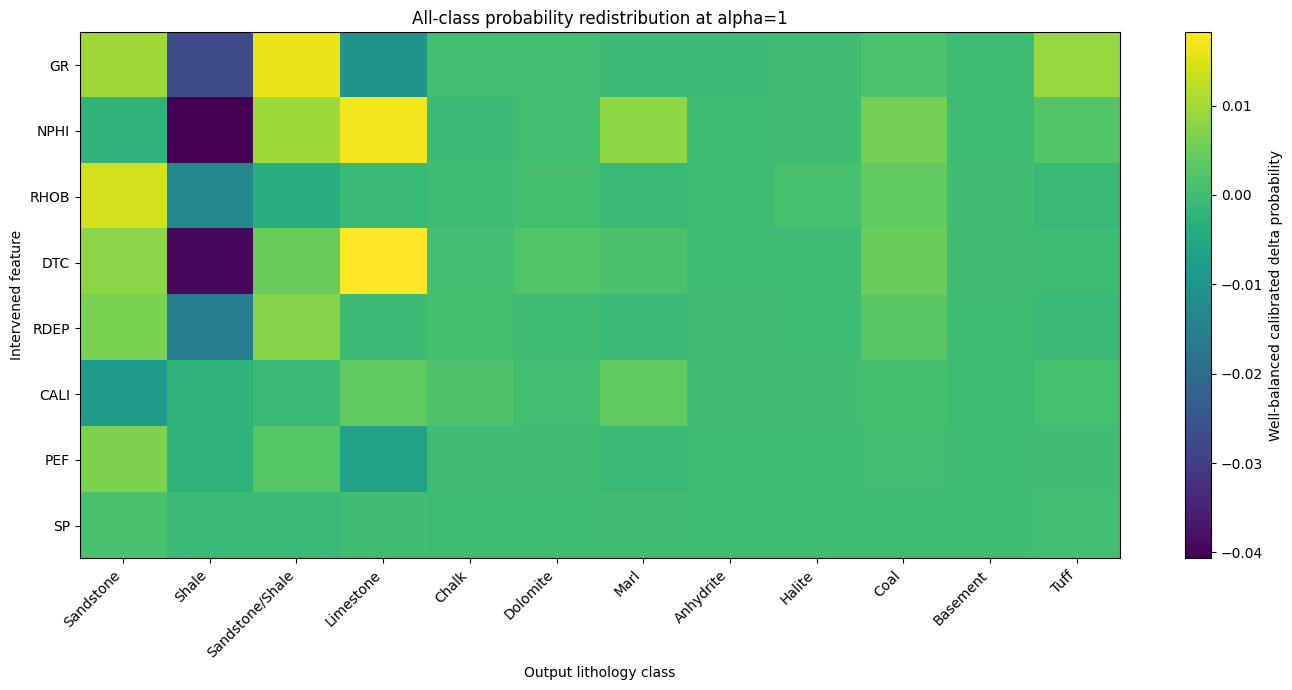

In [15]:
# Plot 01 — Heatmap کامل Probability redistribution در Alpha=1
alpha_one = all_class_summary.loc[
    np.isclose(
        all_class_summary[
            "alpha"
        ],
        1.0,
    )
].copy()

heatmap = alpha_one.pivot_table(
    index="feature",
    columns="output_class_name",
    values="well_balanced_mean_calibrated_delta_probability",
    aggfunc="mean",
)

heatmap = heatmap.reindex(
    index=[
        feature
        for feature in RAW8_FEATURES
        if feature in heatmap.index
    ],
    columns=[
        CLASS_NAMES[
            int(code)
        ]
        for code in CLASSES
        if CLASS_NAMES[
            int(code)
        ] in heatmap.columns
    ],
)

plt.figure(
    figsize=(14, 7)
)

image = plt.imshow(
    heatmap.to_numpy(float),
    aspect="auto",
)

plt.colorbar(
    image,
    label="Well-balanced calibrated delta probability",
)

plt.xticks(
    np.arange(
        len(heatmap.columns)
    ),
    heatmap.columns,
    rotation=45,
    ha="right",
)

plt.yticks(
    np.arange(
        len(heatmap.index)
    ),
    heatmap.index,
)

plt.xlabel(
    "Output lithology class"
)

plt.ylabel(
    "Intervened feature"
)

plt.title(
    "All-class probability redistribution at alpha=1"
)

savefig(
    "01_all_class_probability_redistribution_alpha1.png"
)

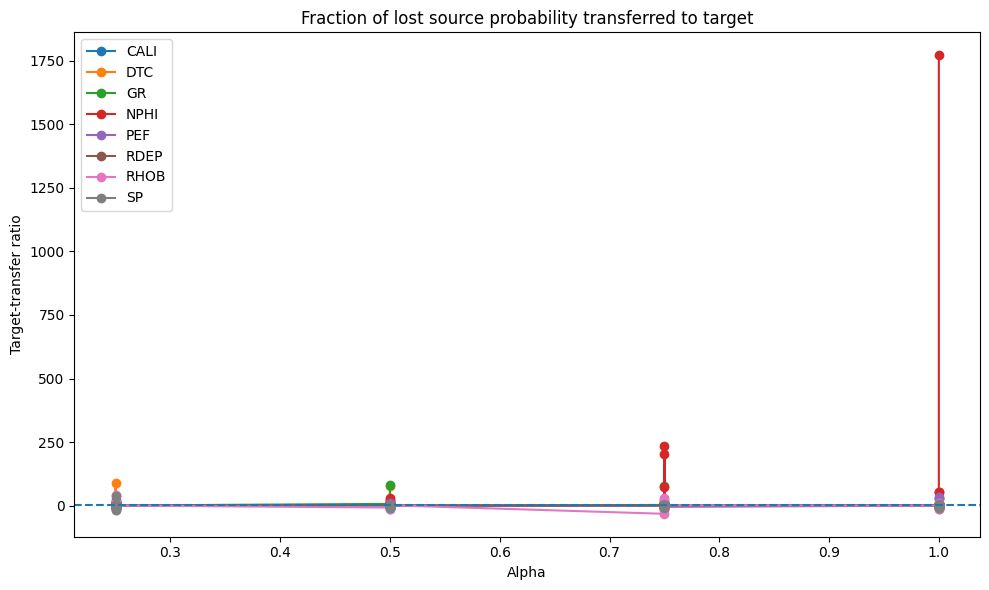

In [16]:
# Plot 02 — Target-transfer ratio by dose
plt.figure(
    figsize=(10, 6)
)

for feature, feature_df in vector_summary.groupby(
    "feature"
):
    feature_df = feature_df.sort_values(
        "alpha"
    )

    plt.plot(
        feature_df[
            "alpha"
        ],
        feature_df[
            "calibrated_target_transfer_ratio"
        ],
        marker="o",
        label=feature,
    )

plt.axhline(
    1.0,
    linestyle="--",
)

plt.xlabel(
    "Alpha"
)

plt.ylabel(
    "Target-transfer ratio"
)

plt.title(
    "Fraction of lost source probability transferred to target"
)

plt.legend()

savefig(
    "02_target_transfer_ratio.png"
)

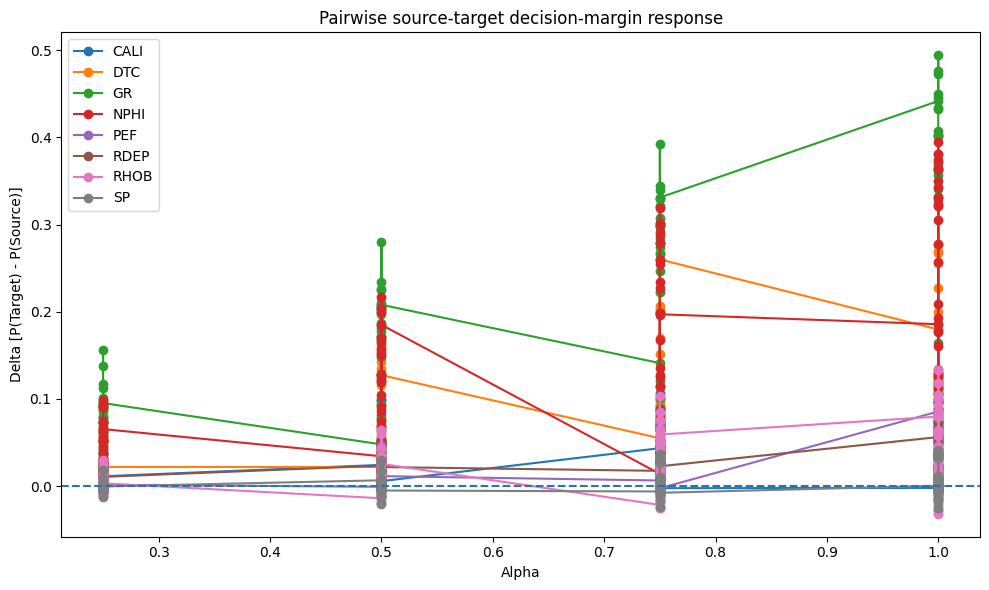

In [17]:
# Plot 03 — Pairwise source-target margin change
plt.figure(
    figsize=(10, 6)
)

for feature, feature_df in vector_summary.groupby(
    "feature"
):
    feature_df = feature_df.sort_values(
        "alpha"
    )

    plt.plot(
        feature_df[
            "alpha"
        ],
        feature_df[
            "mean_calibrated_delta_margin_target_minus_source"
        ],
        marker="o",
        label=feature,
    )

plt.axhline(
    0.0,
    linestyle="--",
)

plt.xlabel(
    "Alpha"
)

plt.ylabel(
    "Delta [P(Target) - P(Source)]"
)

plt.title(
    "Pairwise source-target decision-margin response"
)

plt.legend()

savefig(
    "03_pairwise_margin_response.png"
)

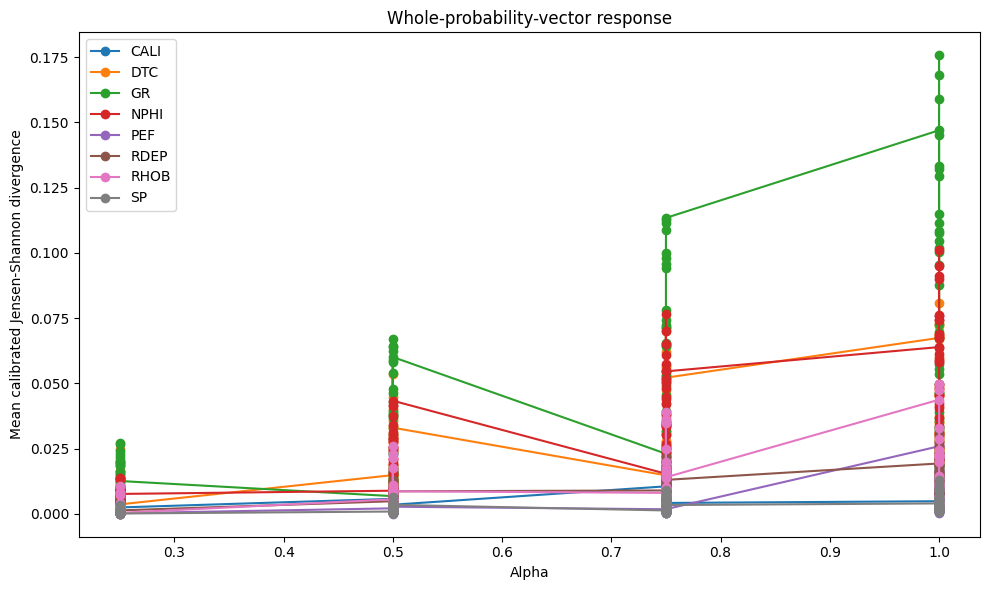

In [18]:
# Plot 04 — کل تغییر بردار Probability
plt.figure(
    figsize=(10, 6)
)

for feature, feature_df in vector_summary.groupby(
    "feature"
):
    feature_df = feature_df.sort_values(
        "alpha"
    )

    plt.plot(
        feature_df[
            "alpha"
        ],
        feature_df[
            "mean_calibrated_JS_divergence"
        ],
        marker="o",
        label=feature,
    )

plt.xlabel(
    "Alpha"
)

plt.ylabel(
    "Mean calibrated Jensen-Shannon divergence"
)

plt.title(
    "Whole-probability-vector response"
)

plt.legend()

savefig(
    "04_probability_vector_JS_response.png"
)

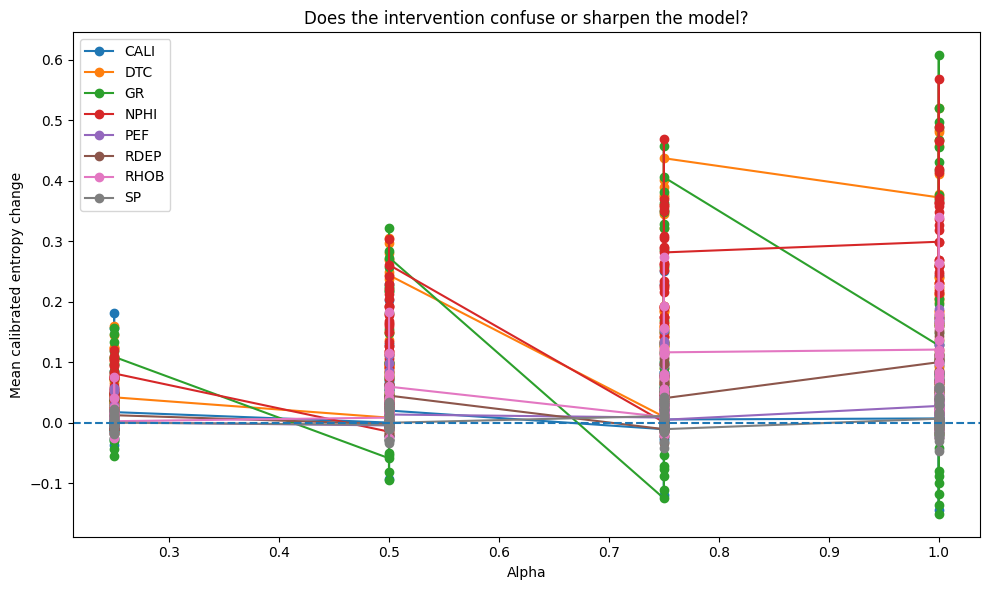

In [19]:
# Plot 05 — Entropy change
plt.figure(
    figsize=(10, 6)
)

for feature, feature_df in vector_summary.groupby(
    "feature"
):
    feature_df = feature_df.sort_values(
        "alpha"
    )

    plt.plot(
        feature_df[
            "alpha"
        ],
        feature_df[
            "mean_calibrated_entropy_change"
        ],
        marker="o",
        label=feature,
    )

plt.axhline(
    0.0,
    linestyle="--",
)

plt.xlabel(
    "Alpha"
)

plt.ylabel(
    "Mean calibrated entropy change"
)

plt.title(
    "Does the intervention confuse or sharpen the model?"
)

plt.legend()

savefig(
    "05_entropy_change.png"
)

In [20]:
expected_condition_count = len(
    selected
)

observed_condition_count = (
    condition_gates[
        "condition_id"
    ].nunique()
)

expected_class_summary_rows = (
    expected_condition_count
    * len(DOSES)
    * len(CLASSES)
)

stage_gate = {
    "official_test_unused": True,
    "05C_passed": bool(
        gate_05c[
            "overall_strict_nested_temperature_calibration_passed"
        ]
    ),
    "06A_passed": bool(
        gate_06a[
            "overall_raw_RF_transport_intervention_stage_passed"
        ]
    ),
    "file12_used_for_control_probabilities": True,
    "frozen_models_used": True,
    "frozen_imputers_used": True,
    "frozen_temperatures_used": True,
    "no_refitting": True,
    "all_fold_replays_passed": bool(
        replay_df[
            "replay_passed"
        ].all()
    ),
    "all_condition_gates_passed": bool(
        condition_gates[
            "condition_gate_passed"
        ].all()
    ),
    "expected_condition_count": int(
        expected_condition_count
    ),
    "observed_condition_count": int(
        observed_condition_count
    ),
    "condition_count_correct": (
        observed_condition_count
        == expected_condition_count
    ),
    "expected_all_class_summary_rows": int(
        expected_class_summary_rows
    ),
    "observed_all_class_summary_rows": int(
        len(all_class_summary)
    ),
    "all_class_summary_row_count_correct": (
        len(all_class_summary)
        == expected_class_summary_rows
    ),
    "probability_mass_conserved": bool(
        np.allclose(
            all_class_summary.groupby(
                [
                    "condition_id",
                    "alpha",
                ]
            )[
                "pooled_mean_calibrated_delta_probability"
            ]
            .sum()
            .to_numpy(float),
            0.0,
            rtol=0.0,
            atol=1e-8,
        )
    ),
    "row_level_all_class_saved": bool(
        SAVE_ROW_LEVEL_ALL_CLASS
    ),
    "run_mode": RUN_MODE,
}

stage_gate[
    "overall_all_class_probability_redistribution_passed"
] = bool(
    stage_gate[
        "official_test_unused"
    ]
    and stage_gate[
        "05C_passed"
    ]
    and stage_gate[
        "06A_passed"
    ]
    and stage_gate[
        "file12_used_for_control_probabilities"
    ]
    and stage_gate[
        "frozen_models_used"
    ]
    and stage_gate[
        "frozen_imputers_used"
    ]
    and stage_gate[
        "frozen_temperatures_used"
    ]
    and stage_gate[
        "no_refitting"
    ]
    and stage_gate[
        "all_fold_replays_passed"
    ]
    and stage_gate[
        "all_condition_gates_passed"
    ]
    and stage_gate[
        "condition_count_correct"
    ]
    and stage_gate[
        "all_class_summary_row_count_correct"
    ]
    and stage_gate[
        "probability_mass_conserved"
    ]
)

print(
    json.dumps(
        stage_gate,
        indent=2,
    )
)

if not stage_gate[
    "overall_all_class_probability_redistribution_passed"
]:
    raise RuntimeError(
        "06A2 stage gate failed."
    )

replay_df.to_csv(
    OUT / "00_frozen_model_replay_audit.csv",
    index=False,
)

selected.to_csv(
    OUT / "01_selected_conditions.csv",
    index=False,
)

execution.to_csv(
    OUT / "02_condition_execution_manifest.csv",
    index=False,
)

condition_gates.to_csv(
    OUT / "03_condition_gates.csv",
    index=False,
)

all_class_summary.to_parquet(
    OUT / "04_all_class_probability_redistribution.parquet",
    index=False,
)

all_class_summary.to_csv(
    OUT / "04_all_class_probability_redistribution.csv",
    index=False,
)

vector_summary.to_csv(
    OUT / "05_probability_vector_shift_summary.csv",
    index=False,
)

per_well_all_class.to_parquet(
    OUT / "06_per_well_all_class_probability_effects.parquet",
    index=False,
)

per_well_all_class.to_csv(
    OUT / "06_per_well_all_class_probability_effects.csv",
    index=False,
)

probability_destination_ranking.to_csv(
    OUT / "07_probability_destination_ranking.csv",
    index=False,
)

with open(
    OUT / "08_stage_gate.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        stage_gate,
        file,
        ensure_ascii=False,
        indent=2,
    )

run_configuration = {
    "stage": (
        "06A2_all_class_probability_redistribution"
    ),
    "run_mode": RUN_MODE,
    "official_test_used": False,
    "doses": DOSES,
    "classes": {
        str(code): CLASS_NAMES[
            int(code)
        ]
        for code in CLASSES
    },
    "control_probability_source": str(
        FILE12
    ),
    "selected_condition_source": str(
        SELECTED_CONDITIONS_PATH
    ),
    "row_level_all_class_saved": bool(
        SAVE_ROW_LEVEL_ALL_CLASS
    ),
    "primary_new_outputs": [
        "all-class control/intervention/delta probabilities",
        "source-target margin change",
        "target-transfer ratio",
        "entropy change",
        "Jensen-Shannon divergence",
        "total-variation distance",
        "largest gaining and losing classes",
    ],
    "claim_scope": (
        "model probability redistribution under "
        "retrospective measurement interventions"
    ),
}

with open(
    OUT / "09_run_configuration.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        run_configuration,
        file,
        ensure_ascii=False,
        indent=2,
    )

environment = {
    "python": platform.python_version(),
    "platform": platform.platform(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": scipy.__version__,
    "sklearn": sklearn.__version__,
    "joblib": joblib.__version__,
}

with open(
    OUT / "10_environment.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        environment,
        file,
        ensure_ascii=False,
        indent=2,
    )

print(
    "Outputs saved in:",
    OUT,
)

print(
    "Row-level all-class outputs:",
    ROW_DIR,
)

{
  "official_test_unused": true,
  "05C_passed": true,
  "06A_passed": true,
  "file12_used_for_control_probabilities": true,
  "frozen_models_used": true,
  "frozen_imputers_used": true,
  "frozen_temperatures_used": true,
  "no_refitting": true,
  "all_fold_replays_passed": true,
  "all_condition_gates_passed": true,
  "expected_condition_count": 319,
  "observed_condition_count": 319,
  "condition_count_correct": true,
  "expected_all_class_summary_rows": 15312,
  "observed_all_class_summary_rows": 15312,
  "all_class_summary_row_count_correct": true,
  "probability_mass_conserved": true,
  "row_level_all_class_saved": false,
  "run_mode": "full",
  "overall_all_class_probability_redistribution_passed": true
}
Outputs saved in: <ARTIFACT_ROOT>/06A2_all_class_probability_redistribution/full
Row-level all-class outputs: <ARTIFACT_ROOT>/06A2_all_class_probability_redistribution/full/row_level_all_class
